# M02 prism gravity: production operator and independent oracle

**Question:** Across an exterior transect, how closely does the product SimPEG/Geoana prism operator reproduce Choclo’s analytic vertical gravity for the same 1000 kg/m³ prism?

**Level 3 · Prerequisites: the preceding foundations lesson; estimated reading time: 60 minutes.**

## Objectives

Validate one bounded production forward calculation against Choclo while testing density linearity and receiver-distance effects.

## Setup

Use the repository's pinned Python 3.12 environment. Build it from the repository root with `scripts/setup.ps1 -Notebooks` on Windows or `scripts/setup.sh --notebooks` on Linux/macOS. This command is shown for reference; the notebook does not install packages.

```text
pip install simpeg==0.25.2 geoana==0.8.1 choclo==0.3.2
```

Import the product method and plotting tools once. The next cell reports the active implementation.

In [1]:
# Import repository methods and plotting tools for this lesson.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
import gravity_forward
print('Engine:', gravity_forward.ENGINE)
import choclo
from importlib.metadata import version
print('Choclo:', version('choclo'))


Engine: simpeg-0.25.2-geoana-0.8.1-f64-ram
Choclo: 0.3.2


## Data

The notebook builds a one-cell prism with x,y=[−50,50] m and z=[−100,0] m, density 1000 kg/m³, and 81 receivers at z=100 m. This authored synthetic control is not field data. Production is `data-pipeline/gravity_forward.py`, using SimPEG 0.25.2 and Geoana 0.8.1. The independent analytic comparison uses Choclo 0.3.2 directly with identical bounds, density and receiver coordinates. Product design and validation notes provide provenance for the operator contract.

Read the declared inputs or construct the authored synthetic geometry. No solver output is loaded.

In [2]:
# Construct a one-cell prism and symmetric exterior transect.
mesh = {'origin_m': np.array([-50., -50., -100.]), 'hx_m': np.array([100.]),
        'hy_m': np.array([100.]), 'hz_m': np.array([100.]),
        'active': np.array([True])}
x = np.linspace(-400., 400., 81)
receivers = np.column_stack([x, np.zeros_like(x), np.full_like(x, 100.)])
base = {'schema': 'gravity-prism-forward-request-1',
        'frame': dict(gravity_forward.FRAME), 'mesh': mesh,
        'receivers_m': receivers, 'engine': gravity_forward.ENGINE}
prism_bounds = (-50., 50., -50., 50., -100., 0.)
sparse_receivers = receivers[::10]
offset_receivers = receivers + np.array([0., 150., 0.])
fine_x = np.linspace(-400., 400., 161)
fine_receivers = np.column_stack([fine_x, np.zeros(161), np.full(161, 100.)])
print('Receivers:', len(receivers), '| density: 1000 kg/m3')


Receivers: 81 | density: 1000 kg/m3


## Method

### Physical convention and integral

For density contrast Δρ in volume V, upward acceleration is g_z(r)=G∫_V Δρ(z′−z)/|r−r′|³ dV. Above positive buried mass, g_z is negative under upward-positive convention. The product returns mGal; Choclo’s SI result is multiplied by 10⁵. Coordinate ordering and prism bounds must match or the two calculations describe different experiments.

### Run the product engine

The request fixes local Cartesian east, north, up axes; metres; a one-cell TensorMesh; one active cell; physical density; and exterior receivers. The wrapper checks runtime pins, actual mesh nodes, cell bounds, physical volumes, receiver separation and output arrays. These controls make the method reproducible beyond a bare formula evaluation.

### Change sampling, keep source fixed

A sparse receiver call checks sign and scale, then a dense call resolves the same source along the transect. Only receiver locations change. The profile should be symmetric about x=0 because both prism and line are symmetric. This is a physical invariant to inspect, not an observation fitted by the model.

### Test two physical invariants

A second product calculation doubles density without changing geometry. Newtonian gravity is linear in density, so acceleration should double up to floating-point error. Another moves the line 150 m north and measures the expected reduction and reshaping with distance. Each call has one controlled change; the resulting arrays are actual solver outputs.

### Compare an independent method

Choclo computes a rectangular-prism analytic field independently of the product’s SimPEG/Geoana path. It receives identical bounds, density and receivers. This notebook computes signed differences and a maximum absolute error. Agreement is cross-validation for this bounded forward problem, not proof that either implementation solves an inverse problem correctly.

### State-of-the-art scope

SimPEG is a widely used simulation and inversion framework; Choclo provides analytic potential-field geometries. The comparison is fair because both calculate the same physical quantity with explicit conventions. It is not a runtime benchmark, broad mesh-convergence study, uncertain-geology experiment, survey-processing evaluation or inverse parameter-selection test.

### Keep the inverse boundary separate

A forward oracle cannot establish density recovery. Inversion adds finite acquisition, noise, regularization, bounds, mesh choices and non-uniqueness. The product’s L2 and geometry dossiers have separate pass/fail scope; this clean one-prism comparison does not replace them. Consult the linked validation record before claiming solver acceptance or field readiness.

Run the pinned production operator on the full line; this establishes the predicted profile and Jacobian.

In [3]:
# Evaluate product forward method for production.
production_result_request = {**base, 'density_kg_m3': np.array([1000.])}
production_result = gravity_forward.forward_gravity(production_result_request)
centre = len(production_result['gz_up_mgal']) // 2
print('production_result centre gz:', float(production_result['gz_up_mgal'][centre]), 'mGal')

production_result centre gz: -0.2927236040238318 mGal


Sample the same source at nine stations. Only receiver sampling changes.

In [4]:
# Evaluate product forward method for sparse.
sparse_result_request = {**base, 'receivers_m': sparse_receivers, 'density_kg_m3': np.array([1000.])}
sparse_result = gravity_forward.forward_gravity(sparse_result_request)
centre = len(sparse_result['gz_up_mgal']) // 2
print('sparse_result centre gz:', float(sparse_result['gz_up_mgal'][centre]), 'mGal')

sparse_result centre gz: -0.2927236040238318 mGal


Double density while holding geometry and receivers fixed; Newtonian gravity predicts a factor of two.

In [5]:
# Evaluate product forward method for double.
double_result_request = {**base, 'density_kg_m3': np.array([2000.])}
double_result = gravity_forward.forward_gravity(double_result_request)
centre = len(double_result['gz_up_mgal']) // 2
print('double_result centre gz:', float(double_result['gz_up_mgal'][centre]), 'mGal')

double_result centre gz: -0.5854472080476636 mGal


Move the profile 150 m north to measure lateral-distance sensitivity for this source.

In [6]:
# Evaluate product forward method for offset.
offset_result_request = {**base, 'receivers_m': offset_receivers, 'density_kg_m3': np.array([1000.])}
offset_result = gravity_forward.forward_gravity(offset_result_request)
centre = len(offset_result['gz_up_mgal']) // 2
print('offset_result centre gz:', float(offset_result['gz_up_mgal'][centre]), 'mGal')

offset_result centre gz: -0.10495285561200406 mGal


Re-evaluate a 161-station line; this is a separate solver execution at finer sampling.

In [7]:
# Evaluate product forward method for fine.
fine_result_request = {**base, 'receivers_m': fine_receivers, 'density_kg_m3': np.array([1000.])}
fine_result = gravity_forward.forward_gravity(fine_result_request)
centre = len(fine_result['gz_up_mgal']) // 2
print('fine_result centre gz:', float(fine_result['gz_up_mgal'][centre]), 'mGal')

fine_result centre gz: -0.2927236040238318 mGal


## State of the art

State-of-the-art scope

SimPEG is a widely used simulation and inversion framework; Choclo provides analytic potential-field geometries. The comparison is fair because both calculate the same physical quantity with explicit conventions. It is not a runtime benchmark, broad mesh-convergence study, uncertain-geology experiment, survey-processing evaluation or inverse parameter-selection test.

Call Choclo's analytic rectangular-prism formula with exactly the same bounds, density and receivers. Convert SI acceleration to mGal.

In [8]:
# Compute the independent analytic oracle on identical physical inputs.
oracle = np.array([choclo.prism.gravity_u(*receiver, *prism_bounds, 1000.) * 1e5
                   for receiver in receivers])
product = production_result['gz_up_mgal']
difference = product - oracle
max_error = float(np.max(np.abs(difference)))
print({'max_abs_difference_mgal': max_error,
       'product_centre_mgal': float(product[len(x) // 2]),
       'oracle_centre_mgal': float(oracle[len(x) // 2])})

{'max_abs_difference_mgal': 7.587680483922554e-15, 'product_centre_mgal': -0.2927236040238318, 'oracle_centre_mgal': -0.29272360402383146}


Compare the production solution with Choclo and inspect signed differences; the residual panel uses a separate scale.

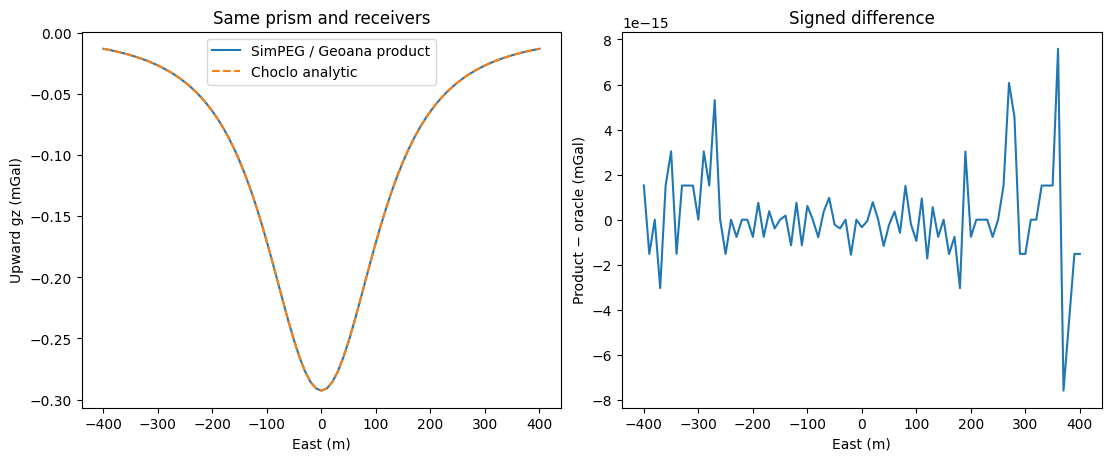

In [9]:
# Plot production and analytic predictions plus signed numerical difference.
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ax.plot(x, product, label='SimPEG / Geoana product')
ax.plot(x, oracle, '--', label='Choclo analytic')
bx.plot(x, difference)
ax.set(xlabel='East (m)', ylabel='Upward gz (mGal)', title='Same prism and receivers')
bx.set(xlabel='East (m)', ylabel='Product − oracle (mGal)', title='Signed difference')
ax.legend()
plt.show()

The upper panel overlays production predictions and Choclo’s analytic oracle on identical exterior receivers; the lower plots product minus oracle in mGal. Symmetry and overlap are visible, while the residual scale exposes numerical disagreement hidden by the main axis. This is one prism and one density, not an inversion fit or field comparison.

Test density scaling and inspect the offset response. These are physical invariants and sensitivity evidence, not visual alternatives.

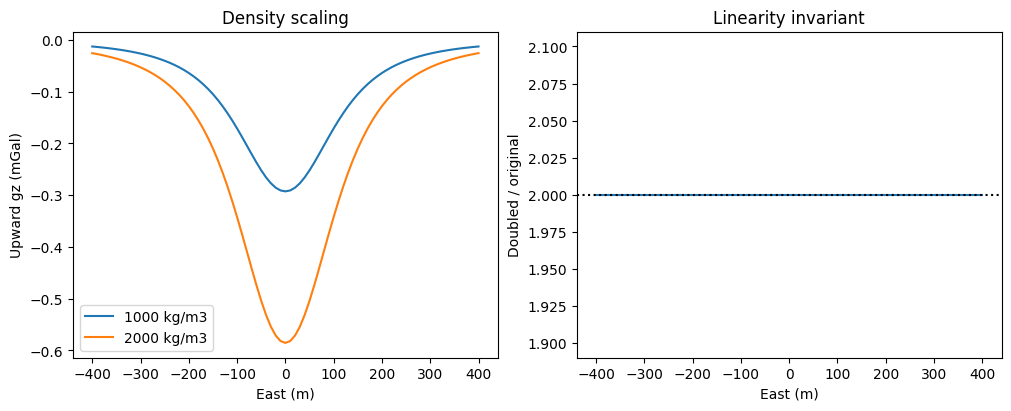

{'max_ratio_error': 0.0, 'fine_line_n': 161, 'offset_centre_mgal': -0.10495285561200406}


In [10]:
# Quantify density linearity and plot the source-distance response.
ratio = double_result['gz_up_mgal'] / production_result['gz_up_mgal']
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax.plot(x, product, label='1000 kg/m3')
ax.plot(x, double_result['gz_up_mgal'], label='2000 kg/m3')
bx.plot(x, ratio)
bx.axhline(2.0, color='black', linestyle=':')
ax.set(xlabel='East (m)', ylabel='Upward gz (mGal)', title='Density scaling')
bx.set(xlabel='East (m)', ylabel='Doubled / original', title='Linearity invariant')
ax.legend()
plt.show()
ratio_error = float(np.max(np.abs(ratio - 2.0)))
print({'max_ratio_error': ratio_error, 'fine_line_n': len(fine_result['gz_up_mgal']),
       'offset_centre_mgal': float(offset_result['gz_up_mgal'][len(x) // 2])})

The second figure tests doubled-density scaling and shows the lateral-offset profile. It quantifies linear amplitude behavior while making distance sensitivity visible. These controls concern one fixed mesh and source. They do not establish arbitrary-mesh convergence, error calibration, inversion stability, or universal accuracy of either engine.

### Comparison limits

Keep the inverse boundary separate

A forward oracle cannot establish density recovery. Inversion adds finite acquisition, noise, regularization, bounds, mesh choices and non-uniqueness. The product’s L2 and geometry dossiers have separate pass/fail scope; this clean one-prism comparison does not replace them. Consult the linked validation record before claiming solver acceptance or field readiness. The discrepancy is reported in mGal.

## Results

**Answer:** The maximum product–Choclo difference is 7.587680483922554e-15 mGal at the tested receivers, and doubled-density ratio error is 0.0. These are bounded forward controls.

In [11]:
# Report the computed cross-engine and physical-invariant evidence.
print({'max_abs_error_mgal': max_error,
       'product_centre_mgal': float(product[len(x) // 2]),
       'choclo_centre_mgal': float(oracle[len(x) // 2]),
       'max_density_ratio_error': ratio_error})

{'max_abs_error_mgal': 7.587680483922554e-15, 'product_centre_mgal': -0.2927236040238318, 'choclo_centre_mgal': -0.29272360402383146, 'max_density_ratio_error': 0.0}


## Summary

The product forward result is checked independently against an analytic prism implementation on identical physical inputs. Agreement supports this bounded case and its sign/unit contract. It does not certify density inversion, field-data eligibility, solver acceptance over a survey matrix, or geological interpretation.

## References

- https://doi.org/10.1016/j.cageo.2015.09.015
- https://www.fatiando.org/choclo/latest/